# Conformal Prediction for Hospital Total Cost

## 1. Setup

### 1.1 Imports and global settings

Imports all libraries and defines the global parameters: file path, target coverage level (`ALPHA`), number of repetitions (`N_REP`), number of CV+ folds (`K`) and the random seed.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import warnings, time
from scipy import stats
from sklearn.model_selection import train_test_split, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
sns.set_style("whitegrid")

ALPHA = 0.10                # target coverage level 1 - alpha = 90%
N_REP = 10                  # number of repetitions 
K = 10                      # number of folds for CV+
SEED = 2026

np.random.seed(SEED)        # reproducibility

### 1.2 Data loading and target construction

Loads the CSV, keeps only patients with a valid (strictly positive) total cost, and creates the target `log_totcst` (the cost is very right-skewed, so we model its logarithm). Also builds the lists of numeric and categorical variables used in the EDA.

In [2]:
raw = pd.read_csv(r"C:\Users\tamim\Desktop\ML\Project\support2.csv", index_col=0)
print("Raw shape:", raw.shape)
print("Missing totcst:", raw["totcst"].isna().sum(), "| totcst <= 0:", (raw["totcst"] <= 0).sum())

# Working dataset for EDA: patients with a valid cost
df = raw[raw["totcst"] > 0].copy()
df["log_totcst"] = np.log(df["totcst"])
TARGET = "log_totcst"
cat_all = df.select_dtypes("object").columns.tolist()
num_all = [c for c in df.select_dtypes("number").columns if c not in ["totcst", TARGET]]
print(f"EDA dataset: n = {len(df)} | {len(num_all)} numeric, {len(cat_all)} categorical variables")

df.head()

Raw shape: (9105, 47)
Missing totcst: 888 | totcst <= 0: 17
EDA dataset: n = 8200 | 38 numeric, 8 categorical variables


,age,death,sex,hospdead,slos,d.time,dzgroup,dzclass,num.co,edu,...,sod,ph,glucose,bun,urine,adlp,adls,sfdm2,adlsc,log_totcst
15,43.53998,0,female,0,115,2022,ARF/MOSF w/Sepsis,ARF/MOSF,1,NaN,...,134.0,7.399414,NaN,NaN,NaN,NaN,NaN,SIP>=30,2.764160,12.875082
18,63.66299,1,female,1,14,14,ARF/MOSF w/Sepsis,ARF/MOSF,0,22.0,...,130.0,7.449219,NaN,NaN,NaN,NaN,0.0,<2 mo. follow-up,0.000000,11.961923
19,31.84399,1,male,1,15,15,Cirrhosis,COPD/CHF/Cirrhosis,2,16.0,...,122.0,NaN,NaN,NaN,NaN,7.0,7.0,<2 mo. follow-up,7.000000,9.771580
22,48.70398,1,male,0,23,30,Lung Cancer,Cancer,0,16.0,...,133.0,7.519531,NaN,NaN,NaN,NaN,NaN,<2 mo. follow-up,3.263672,10.404339
23,49.61298,0,female,0,50,2019,ARF/MOSF w/Sepsis,ARF/MOSF,1,12.0,...,130.0,7.399414,NaN,NaN,NaN,NaN,5.0,adl>=4 (>=5 if sur),5.000000,12.572770


## 2. Data overview and descriptive statistics

### 2.1 Types, unique values and missing values

Summary table of each variable: data type, number of distinct values, and the count and percentage of missing values (sorted from most to least missing). Also reports the number of duplicated rows.

In [3]:
print("\n--- Types and unique values ---")
overview = pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "n_unique": df.nunique(),
                         "n_missing": df.isna().sum(),
                         "pct_missing": (df.isna().mean() * 100).round(1)})
print(overview.sort_values("pct_missing", ascending=False).to_string())
print("\nDuplicated rows:", df.duplicated().sum())


--- Types and unique values ---
              dtype  n_unique  n_missing  pct_missing
adlp        float64         8       5015         61.2
urine       float64      1365       4640         56.6
glucose     float64       426       4354         53.1
bun         float64       157       4209         51.3
alb         float64        59       2978         36.3
income       object         4       2686         32.8
adls        float64         8       2629         32.1
totmcst     float64      5516       2587         31.5
bili        float64       285       2325         28.4
pafi        float64      1401       2100         25.6
ph          float64        73       2062         25.1
edu         float64        31       1479         18.0
prg2m       float64        51       1479         18.0
prg6m       float64        88       1465         17.9
sfdm2        object         5       1273         15.5
wblc        float64       476        195          2.4
charges     float64      7756         74         

### 2.2 Descriptive statistics: numeric variables

Classical summary statistics (count, mean, std, quartiles) plus **skewness** and **kurtosis** for every numeric variable and for the raw cost.

In [4]:
print("\n--- Descriptive statistics: numeric variables ---")
desc = df[num_all + ["totcst"]].describe().T
desc["skew"] = df[num_all + ["totcst"]].skew()
desc["kurtosis"] = df[num_all + ["totcst"]].kurt()
print(desc.round(2).to_string())


--- Descriptive statistics: numeric variables ---
           count      mean       std      min      25%       50%       75%         max  skew  kurtosis
age       8200.0     63.00     15.54    18.12    53.21     65.11     74.39      101.85 -0.51     -0.15
death     8200.0      0.69      0.46     0.00     0.00      1.00      1.00        1.00 -0.81     -1.35
hospdead  8200.0      0.25      0.44     0.00     0.00      0.00      1.00        1.00  1.13     -0.72
slos      8200.0     17.28     20.92     3.00     6.00     11.00     19.00      343.00  4.67     35.95
d.time    8200.0    493.88    572.53     3.00    26.00    236.00    797.00     2029.00  1.14      0.16
num.co    8200.0      1.90      1.35     0.00     1.00      2.00      3.00        9.00  0.81      0.60
edu       6721.0     11.76      3.43     0.00    10.00     12.00     14.00       31.00 -0.00      1.52
scoma     8200.0     11.91     24.63     0.00     0.00      0.00      9.00      100.00  2.36      4.96
charges   8126.0  5692

### 2.3 Descriptive statistics: categorical variables

For each categorical variable, shows the frequency and percentage of every level (missing values included).

In [5]:
print("\n--- Descriptive statistics: categorical variables ---")
for c in cat_all:
    vc = df[c].value_counts(dropna=False)
    print(f"\n{c} ({len(vc)} levels)")
    print(pd.DataFrame({"count": vc, "pct": (vc / len(df) * 100).round(1)}).to_string())


--- Descriptive statistics: categorical variables ---

sex (2 levels)
        count   pct
sex                
male     4609  56.2
female   3591  43.8

dzgroup (8 levels)
                   count   pct
dzgroup                       
ARF/MOSF w/Sepsis   3102  37.8
CHF                 1292  15.8
COPD                 898  11.0
Lung Cancer          829  10.1
MOSF w/Malig         627   7.6
Coma                 535   6.5
Cirrhosis            460   5.6
Colon Cancer         457   5.6

dzclass (4 levels)
                    count   pct
dzclass                        
ARF/MOSF             3729  45.5
COPD/CHF/Cirrhosis   2650  32.3
Cancer               1286  15.7
Coma                  535   6.5

income (5 levels)
            count   pct
income                 
NaN          2686  32.8
under $11k   2586  31.5
$11-$25k     1375  16.8
$25-$50k      948  11.6
>$50k         605   7.4

race (6 levels)
          count   pct
race                 
white      6541  79.8
black      1193  14.5
hispanic    263

## 3. EDA: univariate analysis

### 3.1 Target variable

Compares the raw cost and the log cost: histograms, boxplot and Q-Q plot. This justifies the log transformation (the skewness should drop sharply).

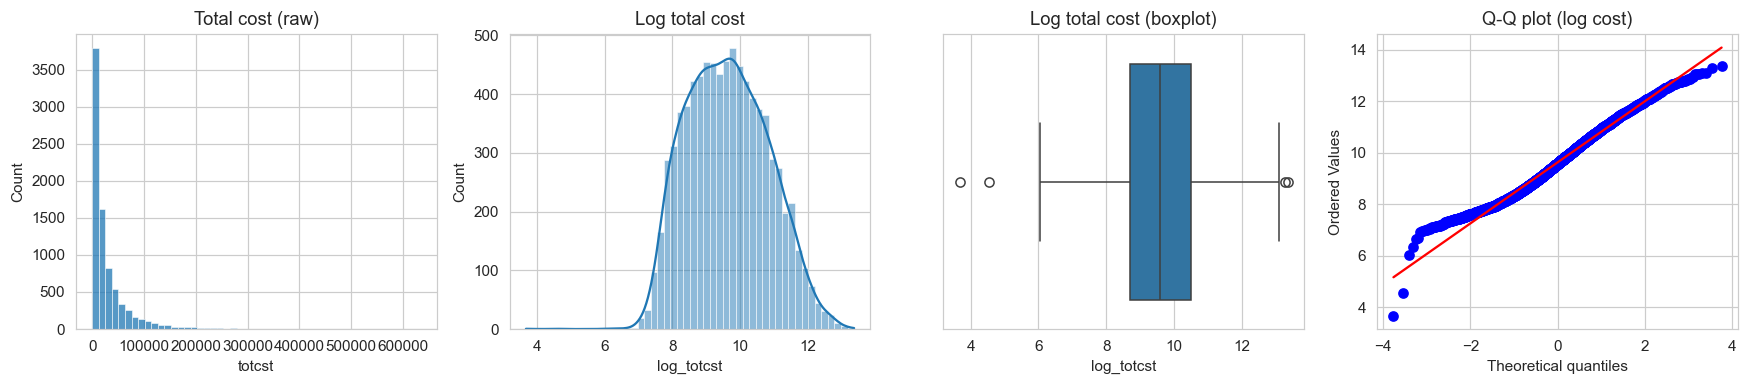

Skewness raw cost: 3.95 | log cost: 0.19


In [6]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
sns.histplot(df["totcst"], bins=50, ax=ax[0]); ax[0].set_title("Total cost (raw)")
sns.histplot(df[TARGET], bins=50, kde=True, ax=ax[1]); ax[1].set_title("Log total cost")
sns.boxplot(x=df[TARGET], ax=ax[2]); ax[2].set_title("Log total cost (boxplot)")
stats.probplot(df[TARGET], dist="norm", plot=ax[3]); ax[3].set_title("Q-Q plot (log cost)")
plt.tight_layout(); plt.savefig("eda_target.png"); plt.show()
print("Skewness raw cost:", round(df["totcst"].skew(), 2), "| log cost:", round(df[TARGET].skew(), 2))

### 3.2 Missing values

Horizontal bar chart of the percentage of missing values for each variable that has at least one.

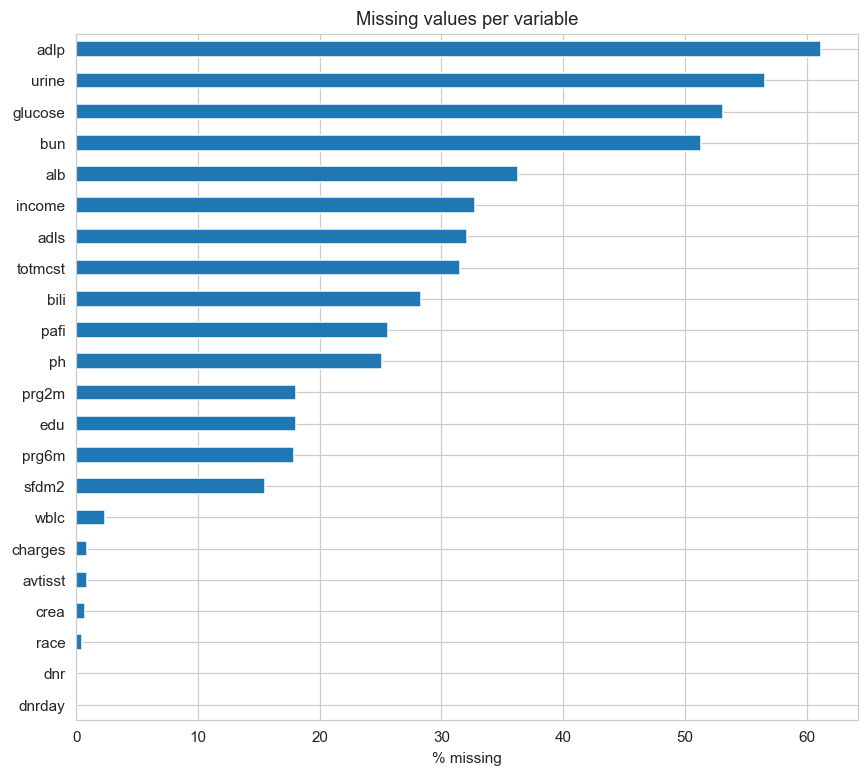

In [7]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
plt.figure(figsize=(8, 0.28 * len(miss) + 1))
miss.sort_values().plot.barh(); plt.xlabel("% missing"); plt.title("Missing values per variable")
plt.tight_layout(); plt.savefig("eda_missing.png"); plt.show()

### 3.3 Numeric variables: histograms

Grid of histograms showing the distribution of every numeric variable (shape, skewness, discrete vs continuous).

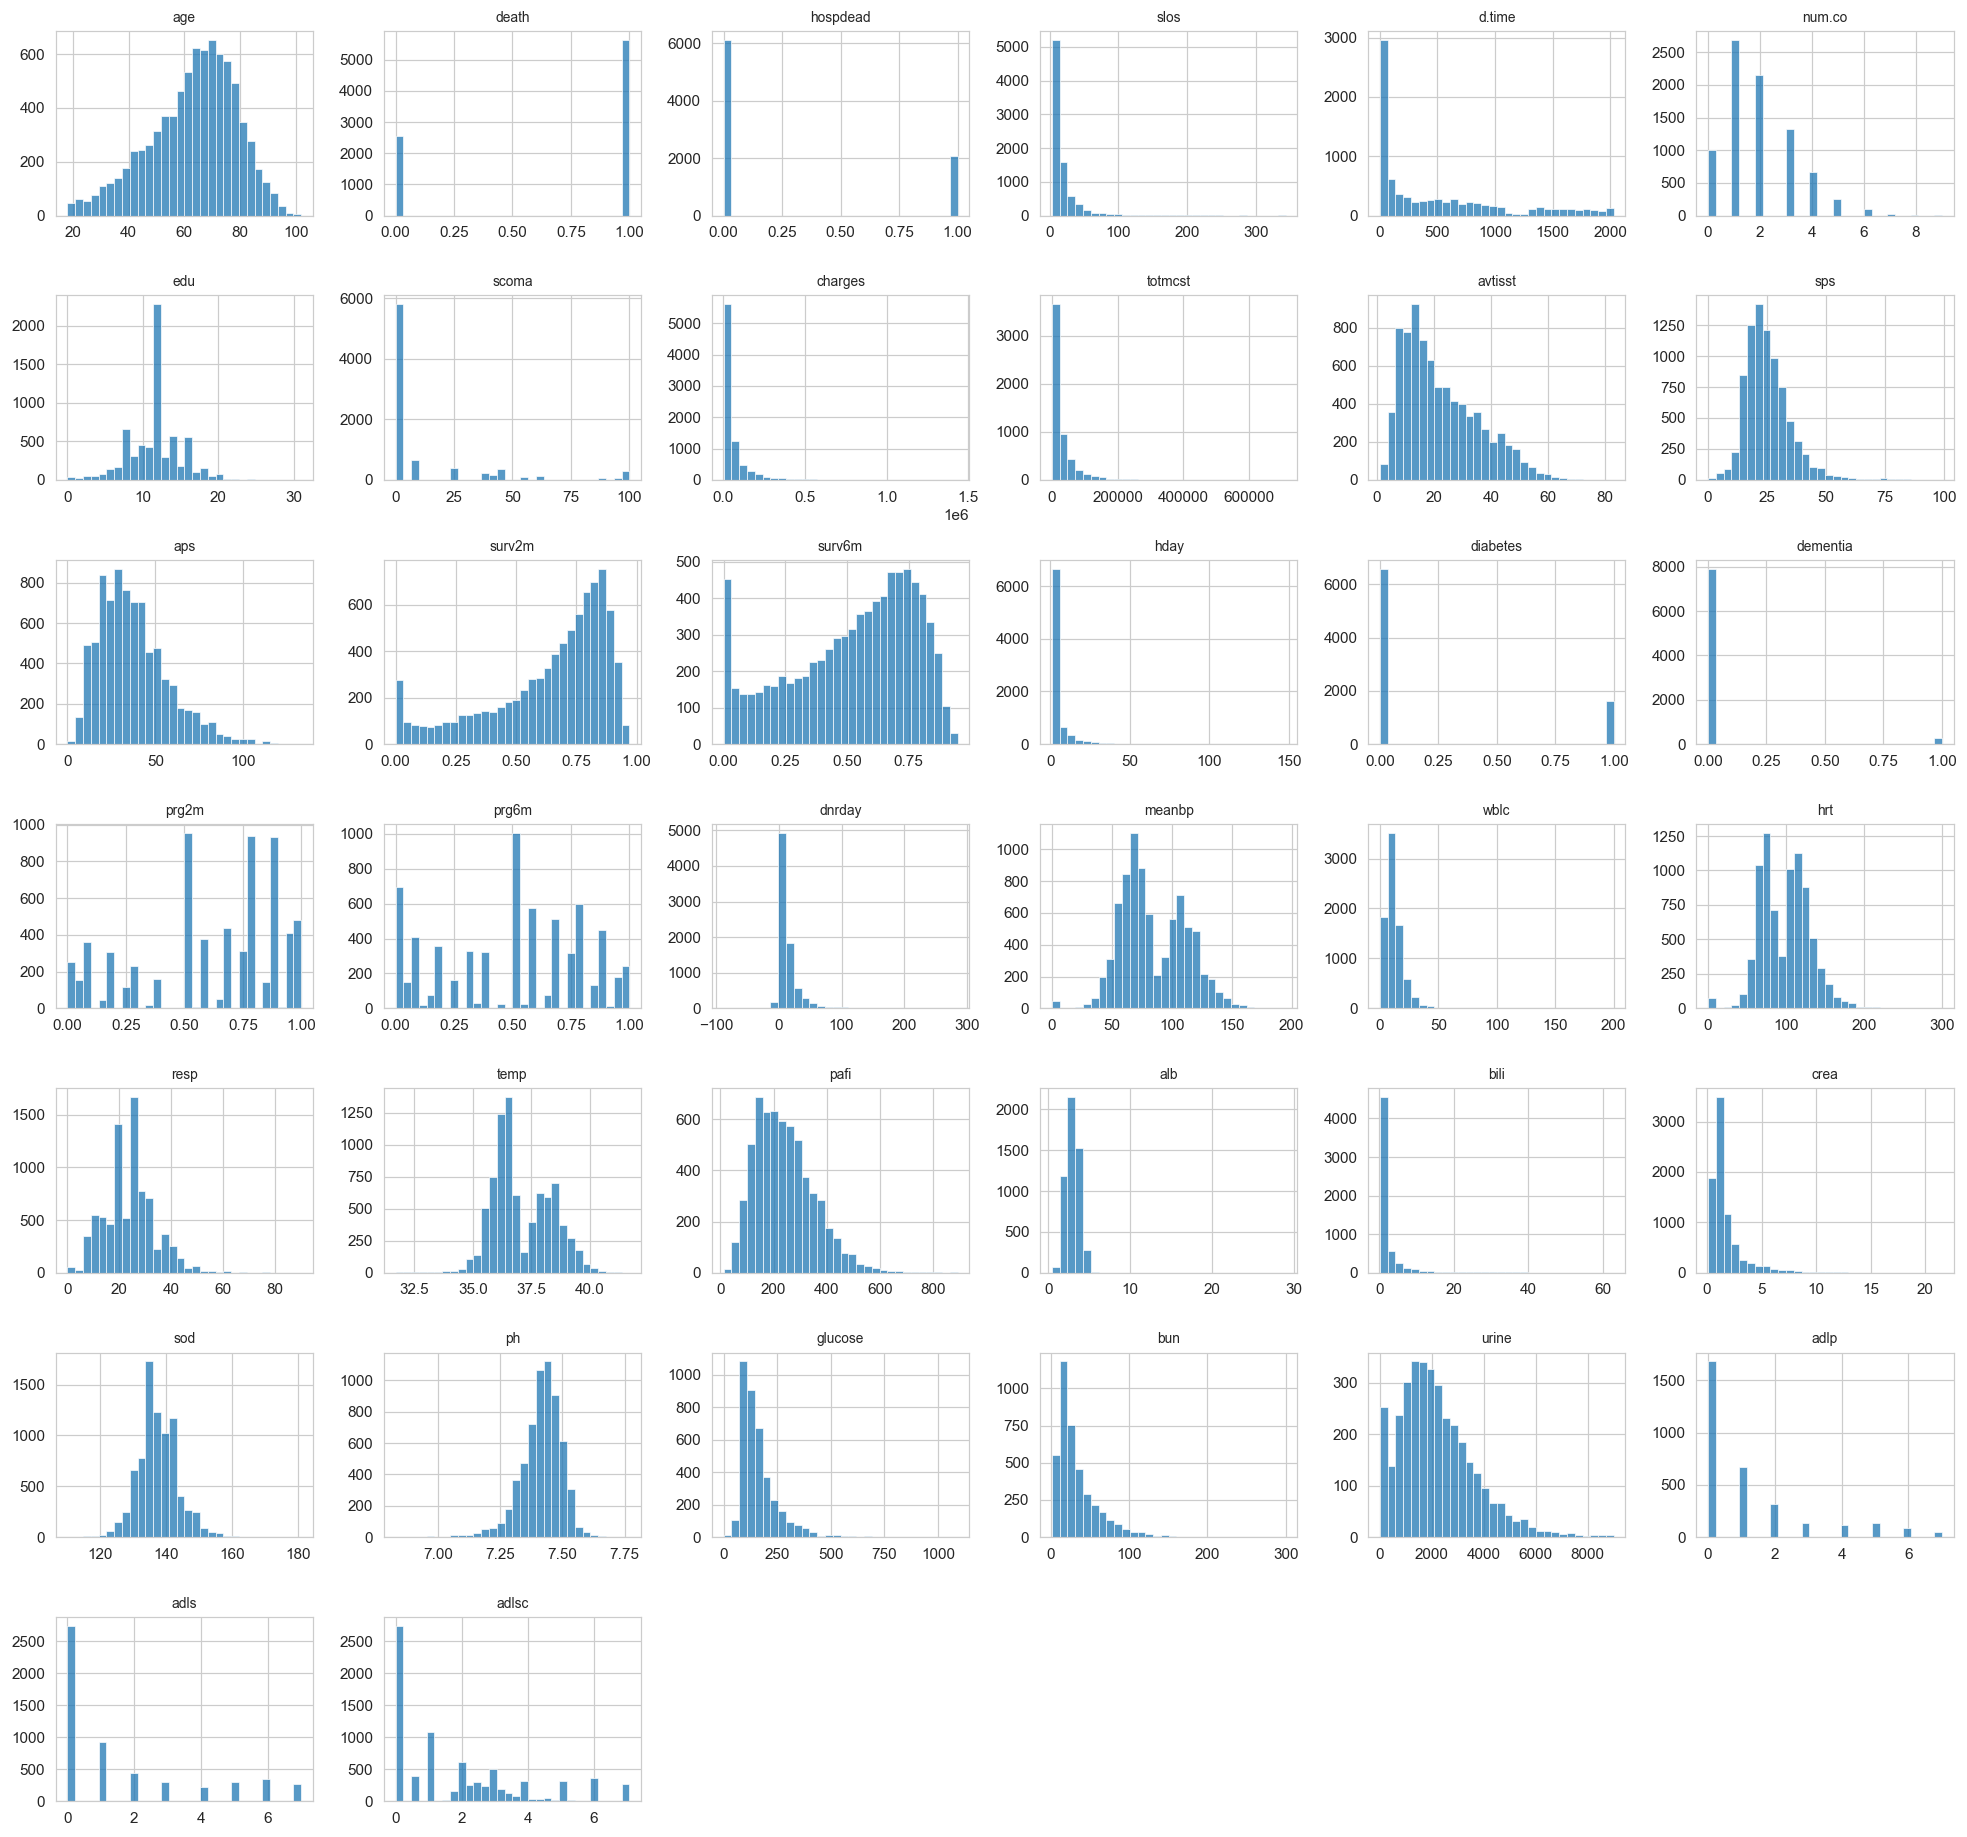

In [8]:
n_cols = 6
n_rows = int(np.ceil(len(num_all) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 2.4 * n_rows))
for a, c in zip(axes.ravel(), num_all):
    sns.histplot(df[c].dropna(), bins=30, ax=a); a.set_title(c, fontsize=9); a.set_xlabel(""); a.set_ylabel("")
for a in axes.ravel()[len(num_all):]:
    a.axis("off")
plt.tight_layout(); plt.savefig("eda_numeric_hist.png"); plt.show()

### 3.4 Categorical variables: bar plots

Frequency bar plots for every categorical variable (missing values shown as their own level).

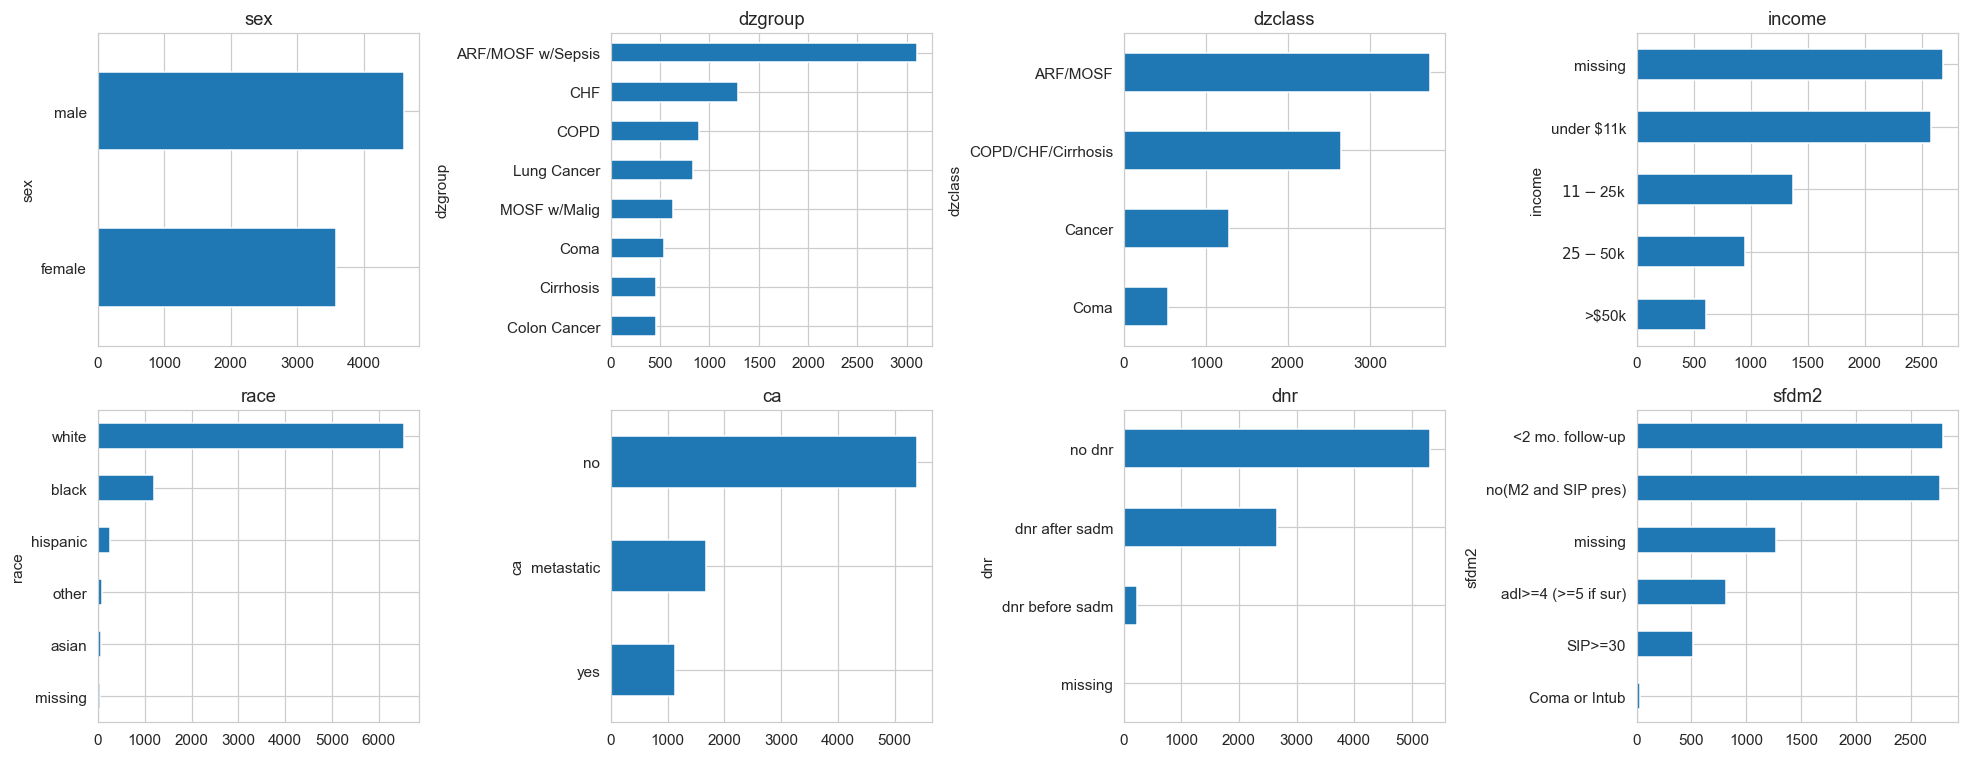

In [9]:
fig, axes = plt.subplots(2, int(np.ceil(len(cat_all) / 2)), figsize=(4.5 * int(np.ceil(len(cat_all) / 2)), 7))
for a, c in zip(axes.ravel(), cat_all):
    df[c].fillna("missing").value_counts().plot.barh(ax=a); a.set_title(c); a.invert_yaxis()
for a in axes.ravel()[len(cat_all):]:
    a.axis("off")
plt.tight_layout(); plt.savefig("eda_categorical_bars.png"); plt.show()

### 3.5 Outliers

Percentage of observations lying outside the 1.5 x IQR fences, for each numeric variable (top 12 shown).

In [10]:
out = {}
for c in num_all:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    out[c] = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).mean() * 100
print("\nOutliers (% outside 1.5*IQR):")
print(pd.Series(out).sort_values(ascending=False).round(1).head(12).to_string())


Outliers (% outside 1.5*IQR):
scoma       21.1
diabetes    19.6
hday        16.7
crea        10.5
charges     10.1
bili        10.0
dnrday       9.0
slos         9.0
totmcst      6.0
wblc         4.2
surv2m       3.6
resp         3.5


## 4. EDA: bivariate analysis (each variable vs the target)

### 4.1 Numeric variables: Spearman correlation with log cost

Ranks numeric variables by the absolute Spearman correlation with the log cost (robust to outliers and non-linear monotone relations) and plots them all.


Spearman correlation with log cost (top 15):
charges     0.977
totmcst     0.954
slos        0.778
avtisst     0.708
dnrday      0.641
hday        0.605
sps         0.484
aps         0.472
surv2m     -0.357
hospdead    0.288
scoma       0.284
prg2m      -0.256
alb        -0.250
surv6m     -0.231
num.co     -0.226


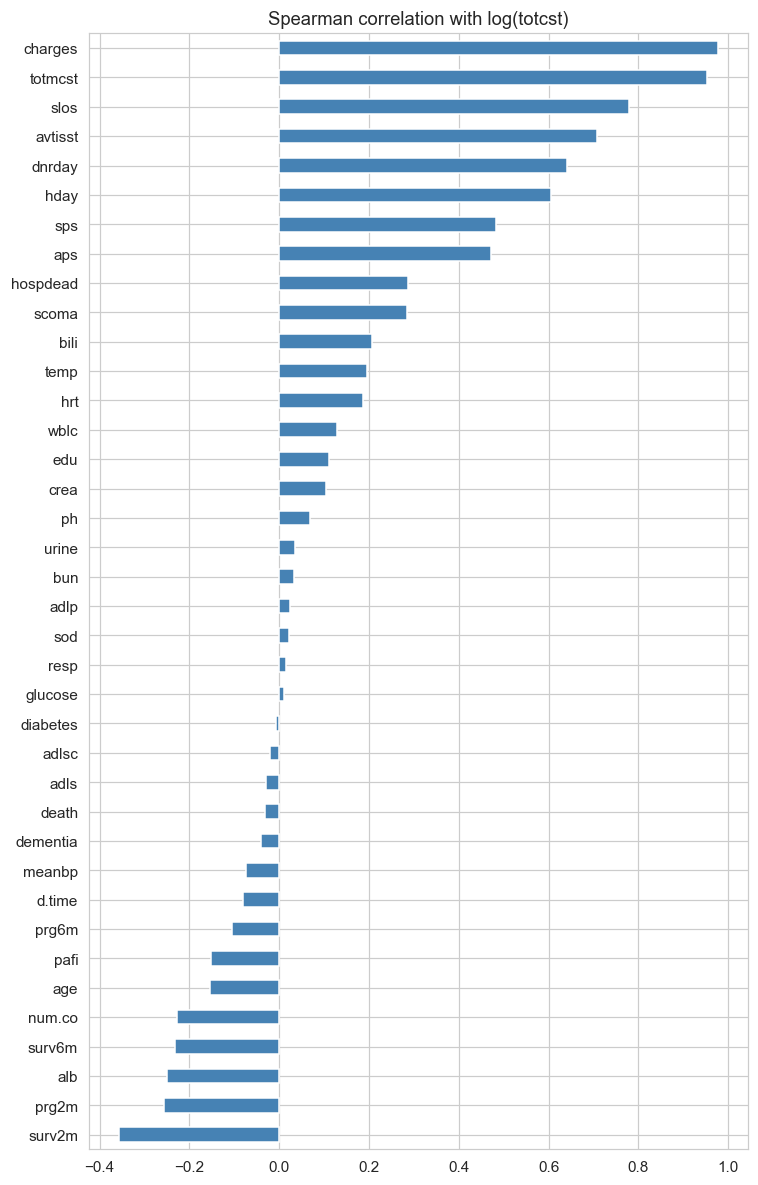

In [11]:
spearman_target = df[num_all + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET)
spearman_target = spearman_target.reindex(spearman_target.abs().sort_values(ascending=False).index)
print("\nSpearman correlation with log cost (top 15):")
print(spearman_target.head(15).round(3).to_string())
plt.figure(figsize=(7, 0.26 * len(spearman_target) + 1))
spearman_target.sort_values().plot.barh(color="steelblue")
plt.title("Spearman correlation with log(totcst)"); plt.tight_layout()
plt.savefig("eda_corr_with_target.png"); plt.show()

### 4.2 Scatter plots: log cost vs the 6 most correlated variables

Scatter plots of the target against the six most correlated numeric predictors (`charges` and `totmcst` are excluded because they are cost variables that leak the target). The red line is the mean of the target within 20 quantile bins of x.

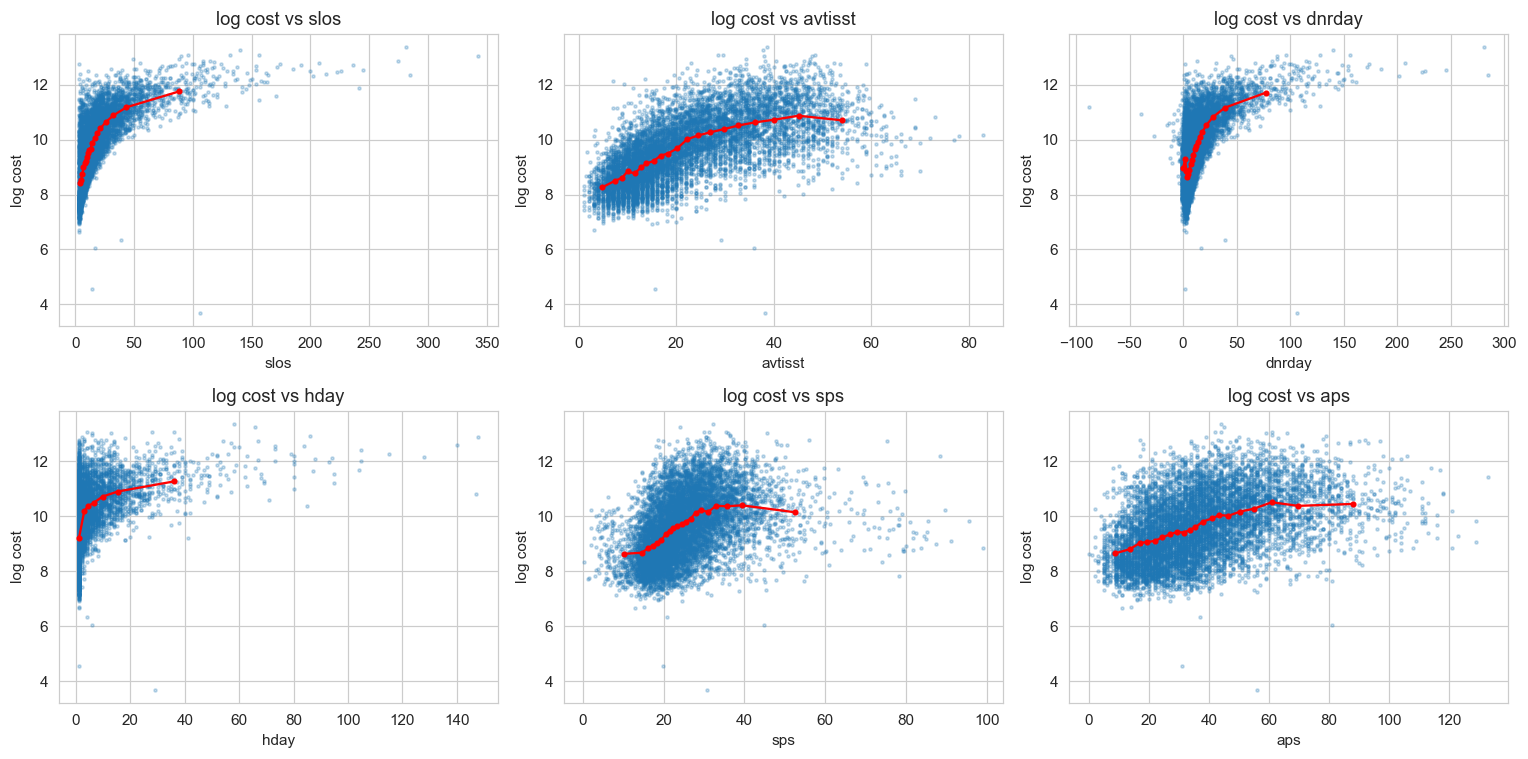

In [12]:
top6 = [c for c in spearman_target.index if c not in ["charges", "totmcst"]][:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for a, c in zip(axes.ravel(), top6):
    a.scatter(df[c], df[TARGET], s=4, alpha=0.25)
    bins = pd.qcut(df[c], 20, duplicates="drop")           # trend line = mean per bin of x
    m = df.groupby(bins)[[c, TARGET]].mean()
    a.plot(m[c], m[TARGET], "r-o", ms=3)
    a.set_xlabel(c); a.set_ylabel("log cost"); a.set_title(f"log cost vs {c}")
plt.tight_layout(); plt.savefig("eda_scatter_top6.png"); plt.show()

### 4.3 Categorical variables: boxplots and Kruskal-Wallis test

Boxplots of the log cost by level of each categorical variable, with a Kruskal-Wallis test (non-parametric ANOVA) to check whether the cost distribution differs between levels.

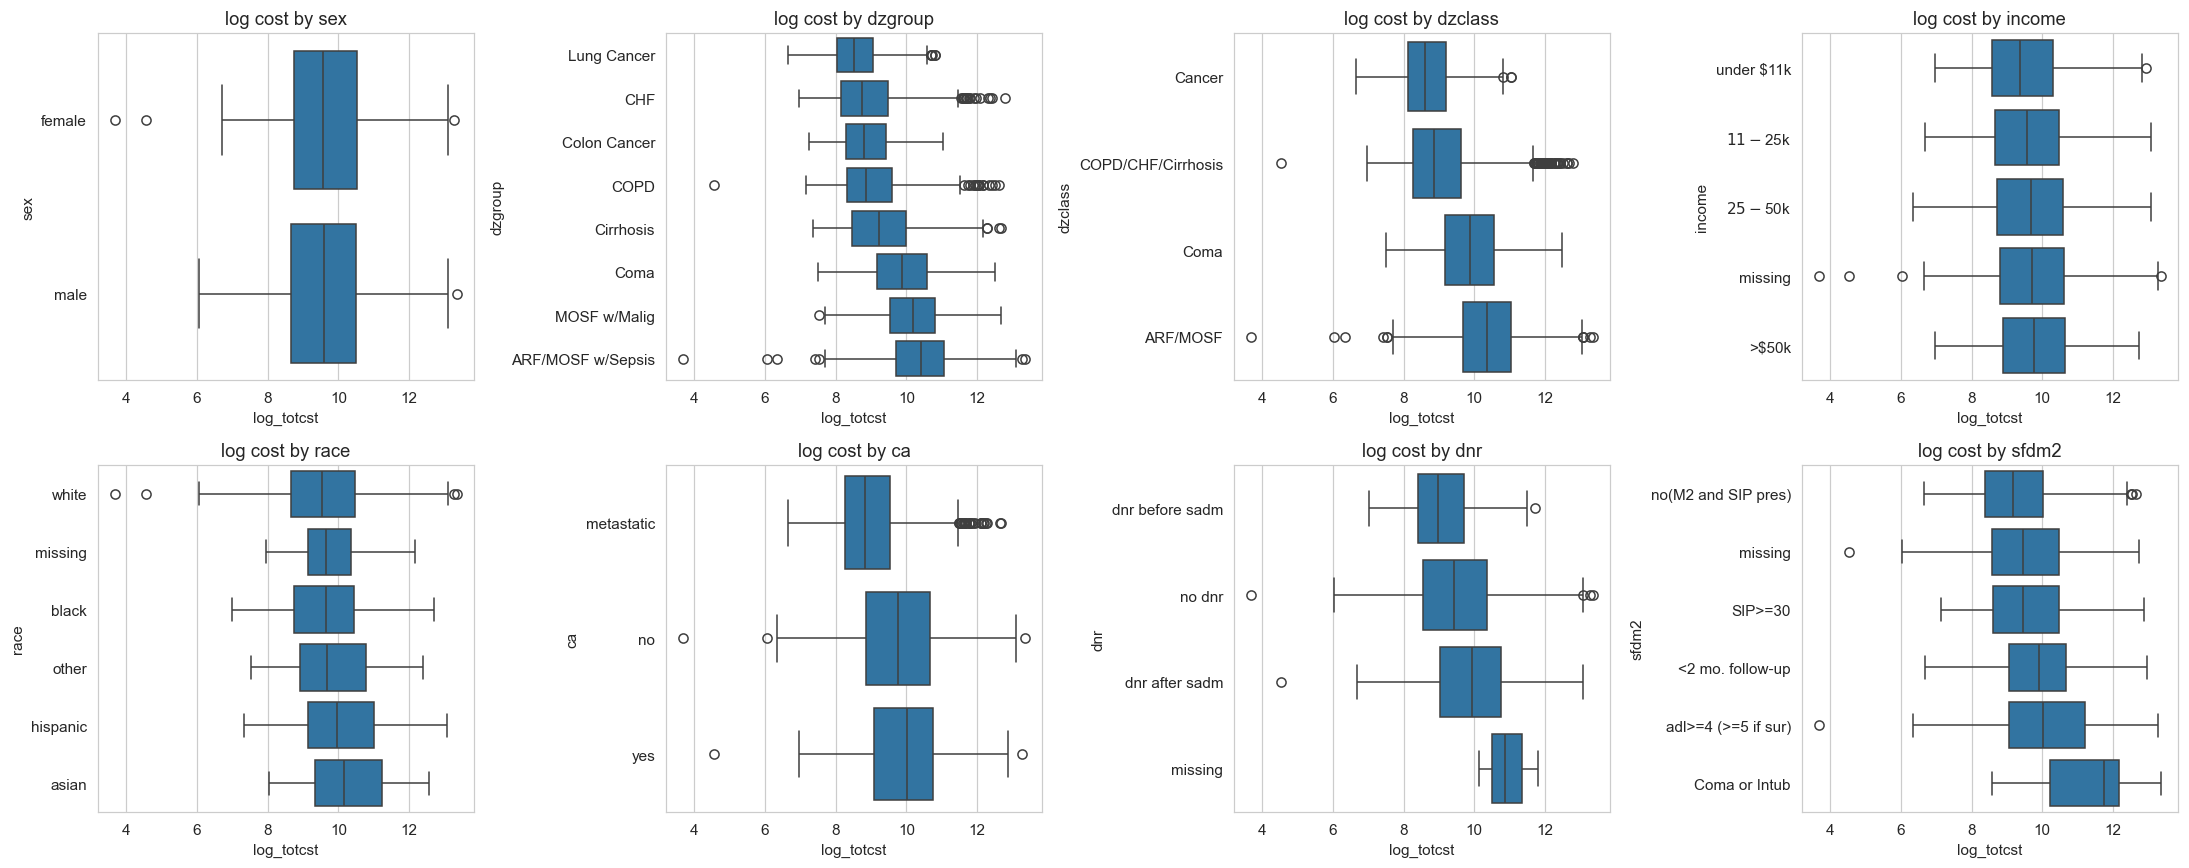


Kruskal-Wallis tests (categorical vs log cost):
variable         H  p_value
     sex    0.5547   0.4564
 dzgroup 3194.3208   0.0000
 dzclass 3116.1997   0.0000
  income   85.2628   0.0000
    race   48.2160   0.0000
      ca  739.4684   0.0000
     dnr  258.5090   0.0000
   sfdm2  545.8302   0.0000


In [13]:
cat_rows = []
fig, axes = plt.subplots(2, int(np.ceil(len(cat_all) / 2)), figsize=(5 * int(np.ceil(len(cat_all) / 2)), 8))
for a, c in zip(axes.ravel(), cat_all):
    tmp = df[[c, TARGET]].copy(); tmp[c] = tmp[c].fillna("missing")
    order = tmp.groupby(c)[TARGET].median().sort_values().index
    sns.boxplot(data=tmp, y=c, x=TARGET, order=order, ax=a); a.set_title(f"log cost by {c}")
    groups = [g[TARGET].values for _, g in tmp.groupby(c) if len(g) > 1]
    h, p = stats.kruskal(*groups)
    cat_rows.append({"variable": c, "H": h, "p_value": p})
for a in axes.ravel()[len(cat_all):]:
    a.axis("off")
plt.tight_layout(); plt.savefig("eda_cat_vs_target.png"); plt.show()
print("\nKruskal-Wallis tests (categorical vs log cost):")
print(pd.DataFrame(cat_rows).round(4).to_string(index=False))

### 4.4 Leakage check

Rank correlation of the cost-related variables (`charges`, `totmcst`) and stay-related variables with the target. Variables almost perfectly correlated with the cost are **leakage** and must not be used as predictors.

In [14]:
print("\nSpearman correlation with log cost (rank-based, so scale-free):")
print(df[["charges", "totmcst", "slos", "avtisst", "d.time", TARGET]].corr(method="spearman")[TARGET].round(3).to_string())


Spearman correlation with log cost (rank-based, so scale-free):
charges       0.977
totmcst       0.954
slos          0.778
avtisst       0.708
d.time       -0.080
log_totcst    1.000


## 5. EDA: multivariate analysis

### 5.1 Correlation matrices (Pearson and Spearman)

Lower-triangular heatmaps of the Pearson (linear) and Spearman (rank) correlation matrices for the numeric predictors and the target, with the leaking cost variables excluded.

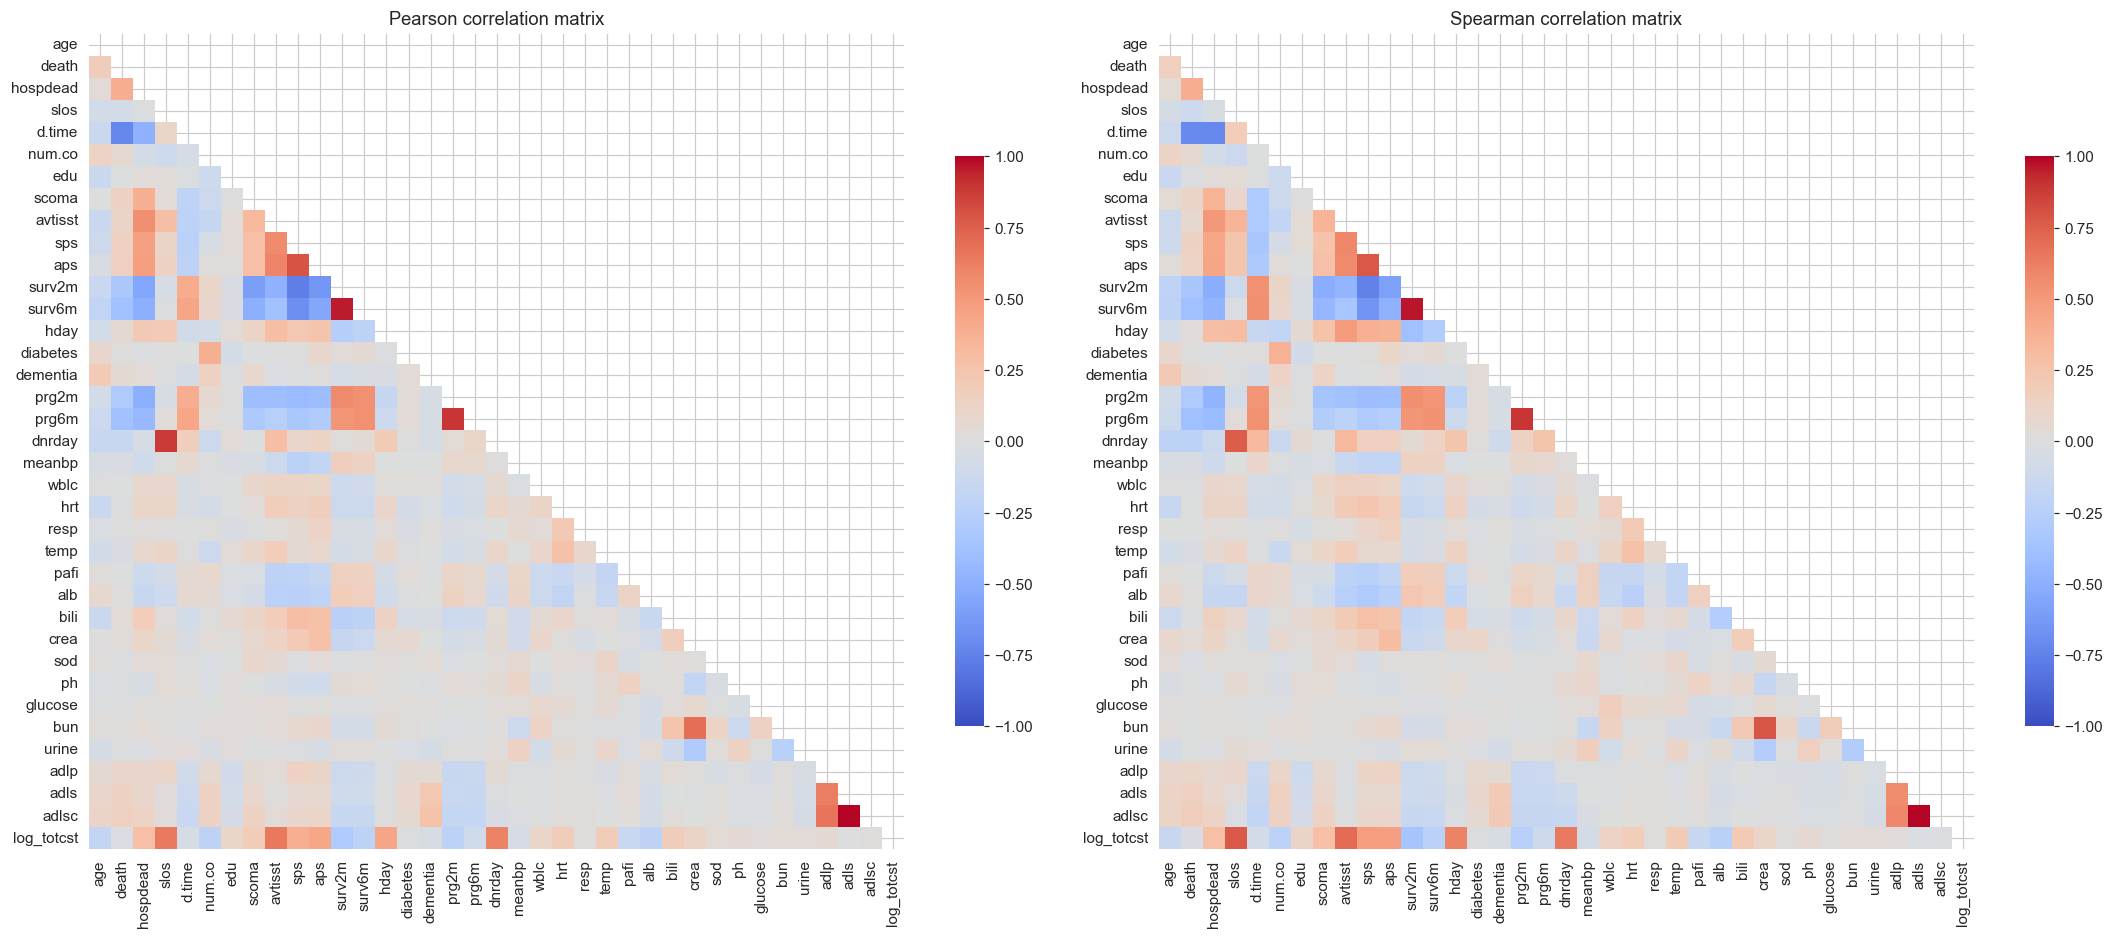

In [15]:
num_feat = [c for c in num_all if c not in ["charges", "totmcst"]]
corr_p = df[num_feat + [TARGET]].corr(method="pearson")
corr_s = df[num_feat + [TARGET]].corr(method="spearman")
mask = np.triu(np.ones_like(corr_s, dtype=bool))
fig, ax = plt.subplots(1, 2, figsize=(20, 9))
sns.heatmap(corr_p, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.6}, ax=ax[0]); ax[0].set_title("Pearson correlation matrix")
sns.heatmap(corr_s, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.6}, ax=ax[1]); ax[1].set_title("Spearman correlation matrix")
plt.tight_layout(); plt.savefig("eda_corr_matrices.png"); plt.show()

### 5.2 Most correlated pairs of predictors

Lists the pairs of predictors with |Spearman rho| > 0.6, to spot redundancy and multicollinearity.

In [16]:
pairs = (corr_s.drop(index=TARGET, columns=TARGET).where(~mask[:-1, :-1]).stack()
              .rename("spearman").reset_index())
pairs.columns = ["var1", "var2", "spearman"]
pairs = pairs.reindex(pairs["spearman"].abs().sort_values(ascending=False).index)
print("\nMost correlated pairs of predictors (|rho| > 0.6):")
print(pairs[pairs["spearman"].abs() > 0.6].round(3).to_string(index=False))


Most correlated pairs of predictors (|rho| > 0.6):
  var1     var2  spearman
 adlsc     adls     1.000
surv6m   surv2m     0.969
 prg6m    prg2m     0.894
   bun     crea     0.784
   aps      sps     0.781
dnrday     slos     0.762
surv2m      sps    -0.743
d.time hospdead    -0.713
d.time    death    -0.708
surv6m      sps    -0.652


### 5.3 Variance inflation factors (VIF)

Median-imputes and standardizes the numeric predictors (matrix `Z`, reused for the PCA below), then computes the VIF of each one. Values above 5-10 indicate strong collinearity.

In [17]:
Z = pd.DataFrame(StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(df[num_feat])),
                 columns=num_feat)
vif = {c: 1 / (1 - LinearRegression().fit(Z.drop(columns=c), Z[c]).score(Z.drop(columns=c), Z[c]))
       for c in num_feat}
print("\nVIF (values above 5-10 indicate strong collinearity):")
print(pd.Series(vif).sort_values(ascending=False).round(2).head(10).to_string())


VIF (values above 5-10 indicate strong collinearity):
surv2m    32.64
surv6m    20.64
prg2m      5.90
prg6m      5.75
sps        5.40
adlsc      4.90
dnrday     4.82
slos       4.62
adls       4.59
aps        3.54


### 5.4 PCA on numeric predictors

Principal component analysis of the standardized numeric predictors: variance explained by the first 10 components (bars) with the cumulative curve (red), and a projection on the first two components colored by log cost.

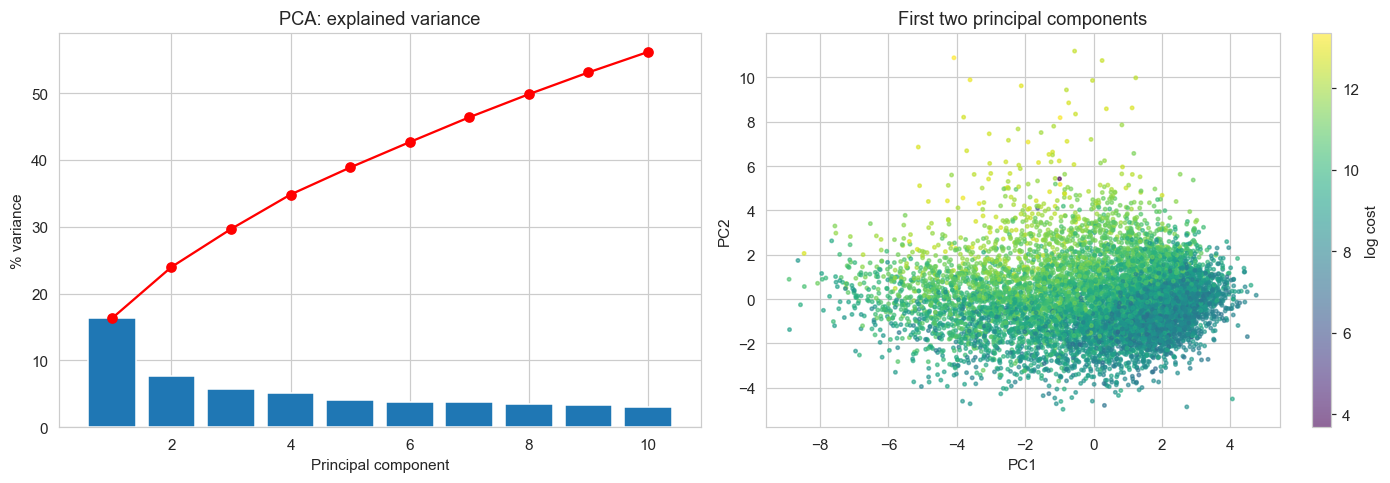

In [18]:
pca = PCA(n_components=10).fit(Z)
proj = pca.transform(Z)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(range(1, 11), pca.explained_variance_ratio_ * 100)
ax[0].plot(range(1, 11), np.cumsum(pca.explained_variance_ratio_) * 100, "r-o")
ax[0].set_xlabel("Principal component"); ax[0].set_ylabel("% variance"); ax[0].set_title("PCA: explained variance")
sc = ax[1].scatter(proj[:, 0], proj[:, 1], c=df[TARGET].values, cmap="viridis", s=5, alpha=0.6)
plt.colorbar(sc, ax=ax[1], label="log cost"); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
ax[1].set_title("First two principal components")
plt.tight_layout(); plt.savefig("eda_pca.png"); plt.show()

### 5.5 Joint effects: diagnosis group x length of stay

Heatmap of the mean log cost for each combination of diagnosis group (`dzgroup`) and length-of-stay quartile (`slos`), to see how the two variables act together.

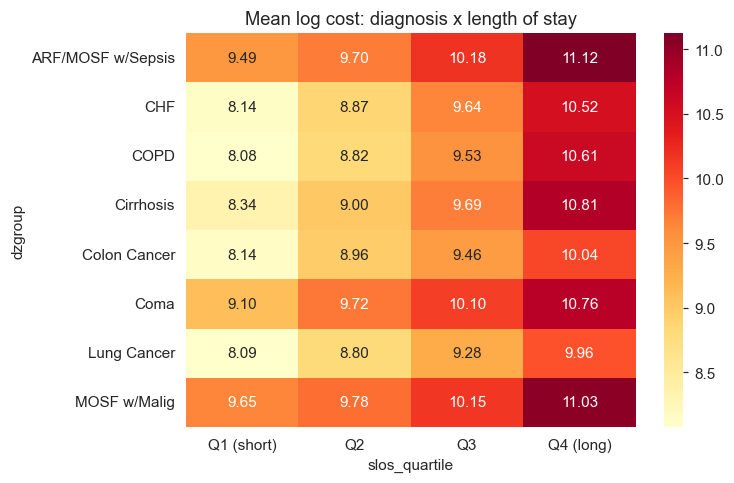

In [19]:
tmp = df[["dzgroup", "slos", TARGET]].copy()
tmp["slos_quartile"] = pd.qcut(tmp["slos"], 4, labels=["Q1 (short)", "Q2", "Q3", "Q4 (long)"])
pivot = tmp.pivot_table(index="dzgroup", columns="slos_quartile", values=TARGET, aggfunc="mean")
plt.figure(figsize=(7, 4.5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlOrRd"); plt.title("Mean log cost: diagnosis x length of stay")
plt.tight_layout(); plt.savefig("eda_joint_dz_slos.png"); plt.show()

### 5.6 Pair plot

Pair plot of the target and the 4 most correlated predictors, on a random sample of 1,500 patients to keep it readable.

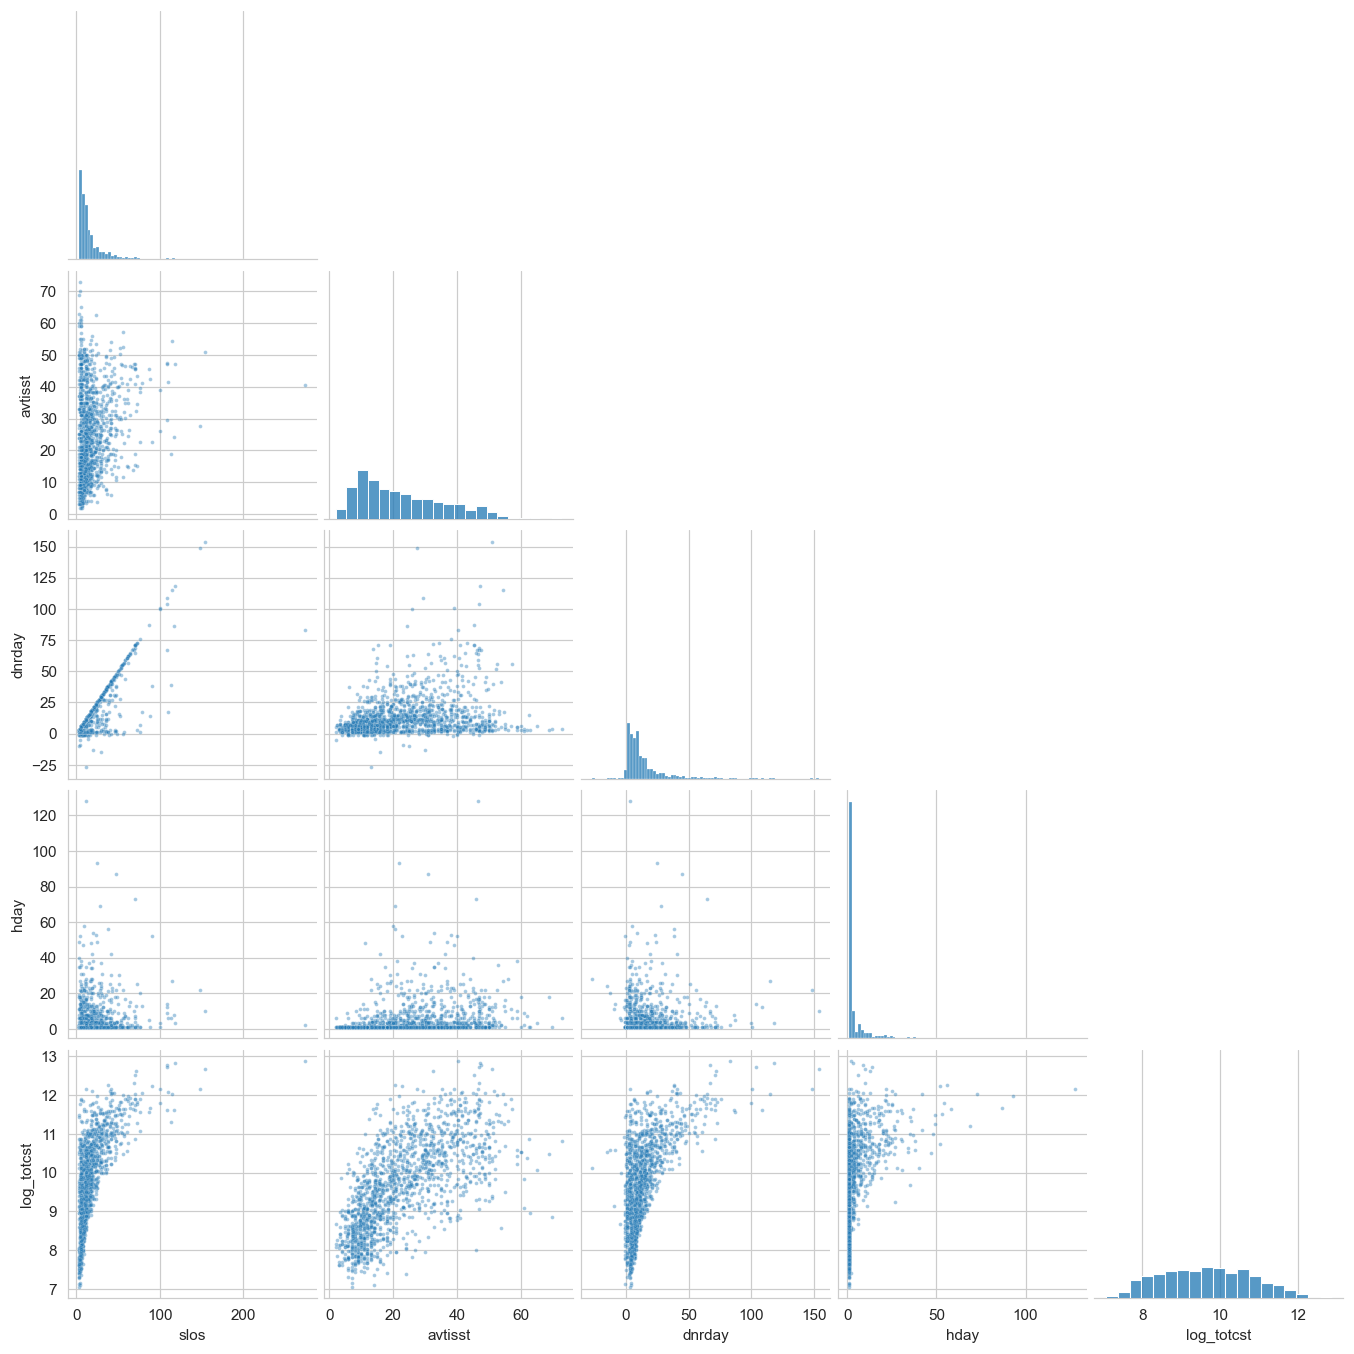

In [20]:
sel = top6[:4] + [TARGET]
sns.pairplot(df[sel].sample(1500, random_state=SEED), corner=True, plot_kws={"s": 6, "alpha": 0.4})
plt.savefig("eda_pairplot.png"); plt.show()

## 6. Preprocessing for modeling

### 6.1 Target, leakage removal and feature selection

Defines the target `y` (log cost) and builds the feature matrix `X`. It drops:
- **Leakage variables:** `totcst`, `charges`, `totmcst` (they are the cost itself or a direct measure of it).
- **Outcome variables** known only after the stay: `death`, `hospdead`, `d.time`, `sfdm2`, `dnr`, `dnrday`.
- **Columns with more than 50% missing values.**

In [21]:
y = df[TARGET].values                       # target: log of total cost
# Leakage (charges, medical cost) and outcome variables (known only after the stay)
DROP = ["totcst", "log_totcst", "charges", "totmcst",
        "death", "hospdead", "d.time", "sfdm2", "dnr", "dnrday"]
X = df.drop(columns=DROP)
dropped_missing = X.columns[X.isna().mean() > 0.50].tolist()
X = X.loc[:, X.isna().mean() <= 0.50]       # drop columns with more than 50% missing values
print("Dropped (>50% missing):", dropped_missing)

cat_cols = X.select_dtypes("object").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print(f"n = {len(X)} | {len(num_cols)} numeric, {len(cat_cols)} categorical predictors")

Dropped (>50% missing): ['glucose', 'bun', 'urine', 'adlp']
n = 8200 | 28 numeric, 6 categorical predictors


### 6.2 Model pipelines

`make_model(kind)` returns a full scikit-learn pipeline (imputation, encoding, estimator):
- **Numeric:** median imputation with missing-value indicators (plus standardization for the linear model).
- **Categorical:** constant imputation (`"missing"`) and one-hot encoding.
- **Estimators:** `lin` = Linear regression, `rf` = Random forest (200 trees, `min_samples_leaf=5`, `max_features=0.5`).

Using a function guarantees that every conformal fit starts from a fresh, unfitted model.

In [22]:
def make_model(kind):
    num_steps = [SimpleImputer(strategy="median", add_indicator=True)]
    if kind == "lin":
        num_steps.append(StandardScaler())
    pre = make_column_transformer(
        (make_pipeline(*num_steps), num_cols),
        (make_pipeline(SimpleImputer(strategy="constant", fill_value="missing"),
                       OneHotEncoder(handle_unknown="ignore")), cat_cols))
    if kind == "lin":
        est = LinearRegression()
    else:
        est = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5,
                                    n_jobs=-1, random_state=SEED)
    return make_pipeline(pre, est)

MODELS = [("Linear regression", "lin"), ("Random forest", "rf")]

## 7. Classical machine learning (point predictions)

### 7.1 Baseline performance

Trains both models with K-fold cross-validation on the development set (mean and standard deviation of R2, RMSE and MAE over the folds), then refits each model on the whole development set and evaluates it on the 20% test set: R2, RMSE and MAE on the log scale, and MAE in dollars. This is the baseline before adding uncertainty with conformal prediction.

In [23]:
from sklearn.model_selection import cross_validate

X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)

cv = KFold(n_splits=K, shuffle=True, random_state=SEED)
scoring = {"R2": "r2",
           "RMSE": "neg_root_mean_squared_error",
           "MAE": "neg_mean_absolute_error"}

rows, fitted = [], {}
for name, kind in MODELS:
    # 1) K-fold cross-validation on the development set
    cvr = cross_validate(make_model(kind), X_dev, y_dev, cv=cv, scoring=scoring)

    # 2) final fit on the whole development set, evaluation on the test set
    m = make_model(kind).fit(X_dev, y_dev)
    fitted[name] = m
    p = m.predict(X_test)

    rows.append({"Model": name,
                 "CV R2": cvr["test_R2"].mean(),
                 "CV R2 sd": cvr["test_R2"].std(),
                 "CV RMSE (log)": -cvr["test_RMSE"].mean(),
                 "CV RMSE sd": cvr["test_RMSE"].std(),
                 "CV MAE (log)": -cvr["test_MAE"].mean(),
                 "Test R2 (log)": r2_score(y_test, p),
                 "Test RMSE (log)": mean_squared_error(y_test, p) ** 0.5,
                 "Test MAE (log)": mean_absolute_error(y_test, p),
                 "Test MAE ($)": mean_absolute_error(np.exp(y_test), np.exp(p))})
baseline = pd.DataFrame(rows)
print(f"{K}-fold CV on the development set + final evaluation on the test set")
print(baseline.round(3).to_string(index=False))

10-fold CV on the development set + final evaluation on the test set
            Model  CV R2  CV R2 sd  CV RMSE (log)  CV RMSE sd  CV MAE (log)  Test R2 (log)  Test RMSE (log)  Test MAE (log)  Test MAE ($)
Linear regression  0.739     0.043          0.609       0.049         0.463          0.759            0.571           0.445     23269.327
    Random forest  0.883     0.024          0.407       0.041         0.299          0.893            0.381           0.295      8654.897


### 7.2 Diagnostics: predicted vs observed and feature importance

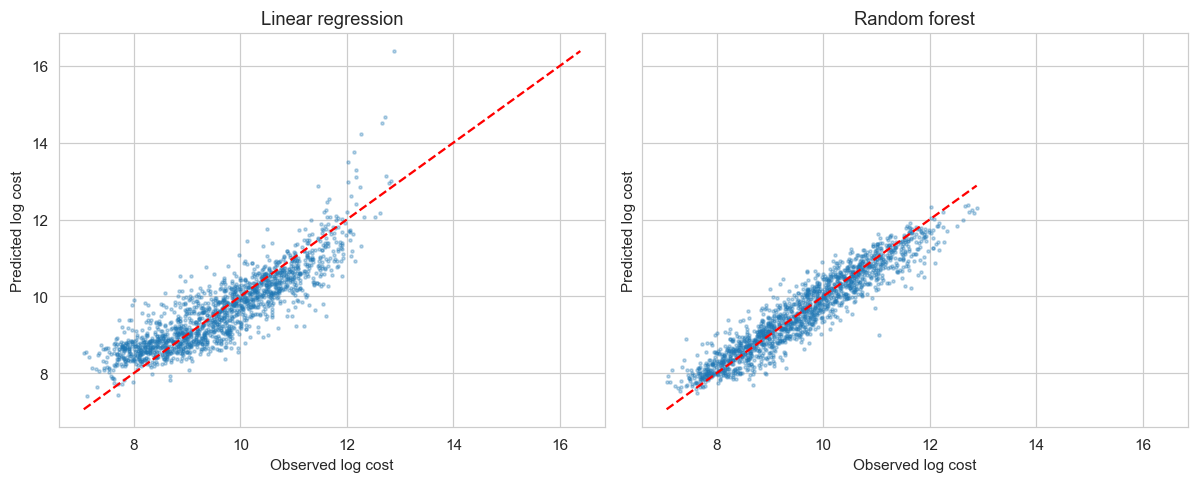

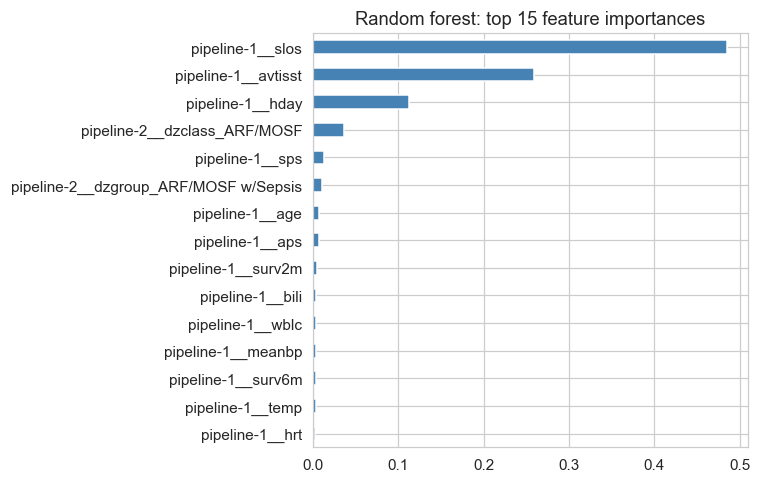

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for a, (name, _) in zip(ax, MODELS):
    p = fitted[name].predict(X_test)
    a.scatter(y_test, p, s=4, alpha=0.3)
    lims = [min(y_test.min(), p.min()), max(y_test.max(), p.max())]
    a.plot(lims, lims, "r--")
    a.set_xlabel("Observed log cost"); a.set_ylabel("Predicted log cost"); a.set_title(name)
plt.tight_layout(); plt.savefig("ml_pred_vs_obs.png"); plt.show()

rf = fitted["Random forest"]
feat_names = rf[0].get_feature_names_out()
imp = pd.Series(rf[-1].feature_importances_, index=feat_names).sort_values(ascending=False).head(15)
plt.figure(figsize=(7, 4.5))
imp.sort_values().plot.barh(color="steelblue")
plt.title("Random forest: top 15 feature importances"); plt.tight_layout()
plt.savefig("ml_rf_importance.png"); plt.show()

## 8. Conformal prediction functions

### 8.1 Split conformal prediction

- `conformal_quantile`: finite-sample corrected quantile `ceil((n+1)(1-alpha))/n` of the conformity scores.
- `split_cp`: splits the development set into 75% training and 25% calibration. The model is trained on the training part, the absolute residuals on the calibration part give the quantile `q`, and the interval is `prediction ± q`.

In [25]:
def conformal_quantile(scores, alpha):
    n = len(scores)
    level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    return np.quantile(scores, level, method="higher")

def split_cp(kind, X_dev, y_dev, X_new, alpha, seed):
    """Split CP: 75% training / 25% calibration of the development set."""
    X_tr, X_cal, y_tr, y_cal = train_test_split(X_dev, y_dev, test_size=0.25, random_state=seed)
    model = make_model(kind).fit(X_tr, y_tr)
    q = conformal_quantile(np.abs(y_cal - model.predict(X_cal)), alpha)
    pred = model.predict(X_new)
    return pred, pred - q, pred + q

### 8.2 CV+ (cross-conformal prediction)


`cv_plus` trains K models, computes the out-of-fold absolute residual of every training point, and builds the interval for a new point with the "plus" construction: lower bound = the `floor(alpha(n+1))`-th smallest value of `mu_{-fold(i)}(x) - R_i`, upper bound = the `ceil((1-alpha)(n+1))`-th smallest value of `mu_{-fold(i)}(x) + R_i`. It uses all the data for both training and calibration, so it is more data-efficient than Split CP but K times more expensive.

In [26]:
def cv_plus(kind, X_dev, y_dev, X_new, alpha, k, seed):
    """CV+: K models, out-of-fold residuals, intervals built with the 'plus' construction."""
    n = len(X_dev)
    fold_of = np.empty(n, dtype=int)
    P_new = np.empty((len(X_new), k))
    resid = np.empty(n)
    for f, (tr, va) in enumerate(KFold(k, shuffle=True, random_state=seed).split(X_dev)):
        model = make_model(kind).fit(X_dev.iloc[tr], y_dev[tr])
        resid[va] = np.abs(y_dev[va] - model.predict(X_dev.iloc[va]))
        P_new[:, f] = model.predict(X_new)
        fold_of[va] = f
    mu = P_new[:, fold_of]                  # prediction of the out-of-fold model of each point i
    lo_all, hi_all = mu - resid, mu + resid
    k_lo = int(np.floor(alpha * (n + 1)))
    k_hi = int(np.ceil((1 - alpha) * (n + 1)))
    lo = np.partition(lo_all, k_lo - 1, axis=1)[:, k_lo - 1]
    hi = np.partition(hi_all, k_hi - 1, axis=1)[:, k_hi - 1]
    return P_new.mean(axis=1), lo, hi

### 8.3 Evaluation metrics

- **RCS** (Regression Coverage Score): fraction of test points whose true value lies inside the interval. It should be close to `1 - alpha`.
- **RMWS** (Regression Mean Width Score): average interval width. For the same coverage, narrower is better.

In [27]:
def rcs(y_true, lo, hi):    # Regression Coverage Score
    return np.mean((y_true >= lo) & (y_true <= hi))

def rmws(lo, hi):           # Regression Mean Width Score
    return np.mean(hi - lo)

## 9. Repeated experiments

### 9.1 Run the 4 combinations N_REP times

For each repetition (a different random train/test split), runs the 4 combinations {Linear regression, Random forest} x {Split CP, CV+} and records RCS, RMWS (log and dollar scale) and RMSE. All test-set intervals are stored in `allp` for the conditional-coverage analysis. Then summarizes the mean and standard deviation of coverage and width.

In [28]:
results, store = [], []
t0 = time.time()
for r in range(N_REP):
    seed = SEED + r
    X_d, X_t, y_d, y_t = train_test_split(X, y, test_size=0.20, random_state=seed)
    for mname, kind in MODELS:
        for cname in ["Split CP", "CV+"]:
            if cname == "Split CP":
                pred, lo, hi = split_cp(kind, X_d, y_d, X_t, ALPHA, seed)
            else:
                pred, lo, hi = cv_plus(kind, X_d, y_d, X_t, ALPHA, K, seed)
            results.append({"rep": r, "Model": mname, "CP method": cname,
                            "RCS": rcs(y_t, lo, hi),
                            "RMWS (log)": rmws(lo, hi),
                            "RMWS ($)": rmws(np.exp(lo), np.exp(hi)),
                            "RMSE (log)": mean_squared_error(y_t, pred) ** 0.5})
            store.append(pd.DataFrame({"rep": r, "Model": mname, "CP method": cname,
                                       "y": y_t, "pred": pred, "lo": lo, "hi": hi,
                                       "dzgroup": X_t["dzgroup"].values}))
    print(f"repetition {r+1}/{N_REP} done ({time.time()-t0:.0f}s)")

res = pd.DataFrame(results)
summary = (res.groupby(["Model", "CP method"])
              .agg(RCS_mean=("RCS", "mean"), RCS_sd=("RCS", "std"),
                   RMWS_log=("RMWS (log)", "mean"), RMWS_dollars=("RMWS ($)", "mean"))
              .round(4))
print(f"\nTarget level 1 - alpha = {1-ALPHA:.2f}")
print(summary)
allp = pd.concat(store, ignore_index=True)

repetition 1/10 done (19s)
repetition 2/10 done (36s)
repetition 3/10 done (53s)
repetition 4/10 done (70s)
repetition 5/10 done (87s)
repetition 6/10 done (104s)
repetition 7/10 done (121s)
repetition 8/10 done (138s)
repetition 9/10 done (155s)
repetition 10/10 done (172s)

Target level 1 - alpha = 0.90
                             RCS_mean  RCS_sd  RMWS_log  RMWS_dollars
Model             CP method                                          
Linear regression CV+          0.8978  0.0098    1.8444   226864.2294
                  Split CP     0.8980  0.0094    1.8540   213259.2227
Random forest     CV+          0.9007  0.0047    1.2343    35529.8625
                  Split CP     0.9013  0.0063    1.2445    35714.8383


### 9.2 Validity check against the theoretical guarantees

Compares the average empirical coverage with the target `1 - alpha` and with the theoretical lower bounds: Split CP guarantees `1 - alpha`, CV+ guarantees `1 - 2*alpha` (and in practice is close to `1 - alpha`). Because the guarantee is marginal and holds in expectation, an average slightly below the target (by about the standard deviation) is not a failure.

In [29]:
theory_bound = {"Split CP": 1 - ALPHA, "CV+": 1 - 2 * ALPHA}
check = summary.reset_index()
check["target"] = 1 - ALPHA
check["theory_lower_bound"] = check["CP method"].map(theory_bound)
check["above_theory_bound"] = check["RCS_mean"] >= check["theory_lower_bound"]
check["gap_to_target"] = (check["RCS_mean"] - check["target"]).round(4)
print(check[["Model", "CP method", "RCS_mean", "RCS_sd", "target",
             "theory_lower_bound", "above_theory_bound", "gap_to_target"]].to_string(index=False))

            Model CP method  RCS_mean  RCS_sd  target  theory_lower_bound  above_theory_bound  gap_to_target
Linear regression       CV+    0.8978  0.0098     0.9                 0.8                True        -0.0022
Linear regression  Split CP    0.8980  0.0094     0.9                 0.9               False        -0.0020
    Random forest       CV+    0.9007  0.0047     0.9                 0.8                True         0.0007
    Random forest  Split CP    0.9013  0.0063     0.9                 0.9                True         0.0013


## 10. Conditional coverage

### 10.1 Coverage by diagnosis group

Conformal prediction only guarantees **marginal** coverage (averaged over all patients). This cell checks whether the coverage is also reasonable within each diagnosis group.

In [30]:
allp["covered"] = (allp["y"] >= allp["lo"]) & (allp["y"] <= allp["hi"])
allp["width"] = allp["hi"] - allp["lo"]

print("\nCoverage by diagnosis group:")
print(allp.groupby(["dzgroup", "Model", "CP method"])["covered"].mean()
          .unstack(["Model", "CP method"]).round(3))


Coverage by diagnosis group:
Model             Linear regression          Random forest         
CP method                       CV+ Split CP           CV+ Split CP
dzgroup                                                            
ARF/MOSF w/Sepsis             0.909    0.909         0.891    0.891
CHF                           0.868    0.866         0.892    0.894
COPD                          0.904    0.903         0.933    0.932
Cirrhosis                     0.874    0.874         0.900    0.899
Colon Cancer                  0.887    0.886         0.924    0.925
Coma                          0.905    0.905         0.891    0.891
Lung Cancer                   0.902    0.902         0.932    0.930
MOSF w/Malig                  0.909    0.916         0.868    0.875


### 10.2 Coverage and width by quintile of the predicted cost

Splits the test points into 5 groups according to the predicted cost (0 = lowest) and reports coverage and mean width in each. With constant-width intervals (absolute residuals), coverage tends to be unbalanced between low-cost and high-cost patients.

In [31]:
allp["pred_quintile"] = allp.groupby(["Model", "CP method"])["pred"].transform(
    lambda s: pd.qcut(s, 5, labels=False, duplicates="drop"))
by_q = (allp.groupby(["Model", "CP method", "pred_quintile"])
            .agg(coverage=("covered", "mean"), width=("width", "mean")).round(3))
print("\nCoverage and width by quintile of the predicted cost (0 = lowest):")
print(by_q)


Coverage and width by quintile of the predicted cost (0 = lowest):
                                           coverage  width
Model             CP method pred_quintile                 
Linear regression CV+       0                 0.919  1.844
                            1                 0.900  1.844
                            2                 0.894  1.844
                            3                 0.895  1.844
                            4                 0.881  1.846
                  Split CP  0                 0.920  1.854
                            1                 0.898  1.854
                            2                 0.894  1.854
                            3                 0.895  1.854
                            4                 0.884  1.854
Random forest     CV+       0                 0.921  1.232
                            1                 0.911  1.234
                            2                 0.899  1.234
                            3                 0

## 11. Figures

### 11.1 Coverage and width of the 4 combinations

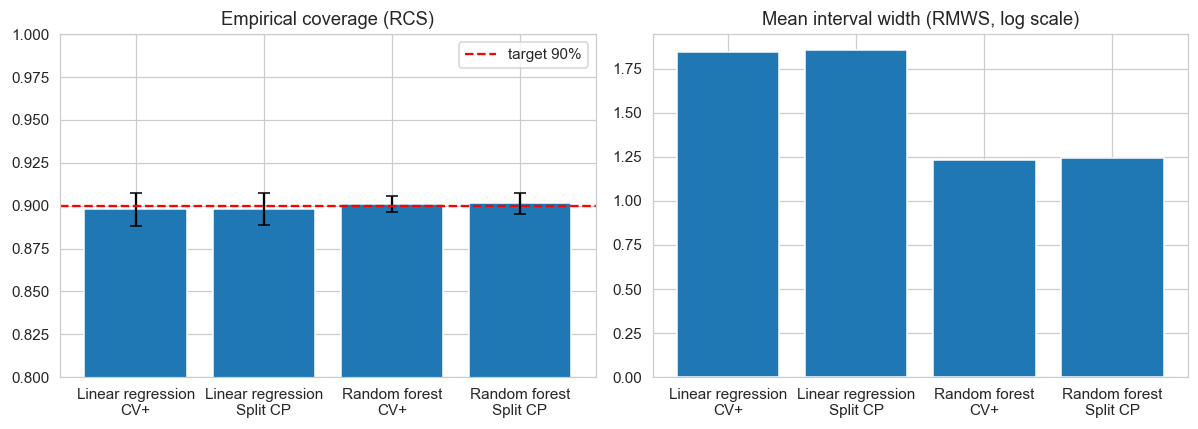

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
lab = [f"{m}\n{c}" for m, c in summary.index]
ax[0].bar(lab, summary["RCS_mean"], yerr=summary["RCS_sd"].fillna(0), capsize=4)
ax[0].axhline(1 - ALPHA, color="red", ls="--", label=f"target {1-ALPHA:.0%}")
ax[0].set_ylim(0.8, 1.0); ax[0].set_title("Empirical coverage (RCS)"); ax[0].legend()
ax[1].bar(lab, summary["RMWS_log"]); ax[1].set_title("Mean interval width (RMWS, log scale)")
plt.tight_layout(); plt.savefig("fig_rcs_rmws.png"); plt.show()

### 11.2 Prediction intervals (CV+)

Test points of the first repetition sorted by predicted value, with the CV+ interval (blue band) and the true values (black dots), for each model.

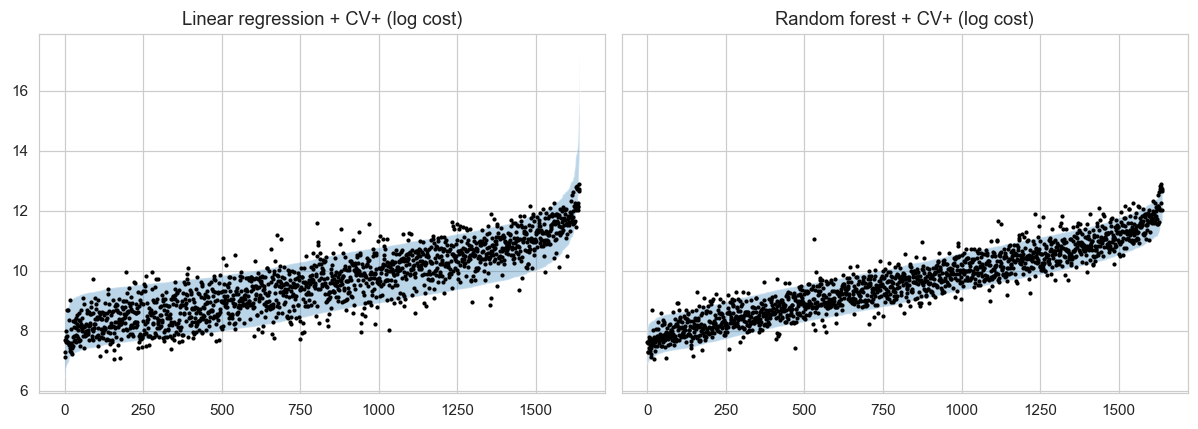

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, (mname, _) in zip(ax, MODELS):
    s = allp[(allp["Model"] == mname) & (allp["CP method"] == "CV+") & (allp["rep"] == 0)] \
          .sort_values("pred").reset_index(drop=True)
    a.fill_between(s.index, s["lo"], s["hi"], alpha=0.3)
    a.scatter(s.index, s["y"], s=3, color="k")
    a.set_title(f"{mname} + CV+ (log cost)")
plt.tight_layout(); plt.savefig("fig_intervals.png"); plt.show()

### 11.3 Coverage by diagnosis group (Random forest + CV+)

Bar chart of the empirical coverage within each diagnosis group, compared with the target level.

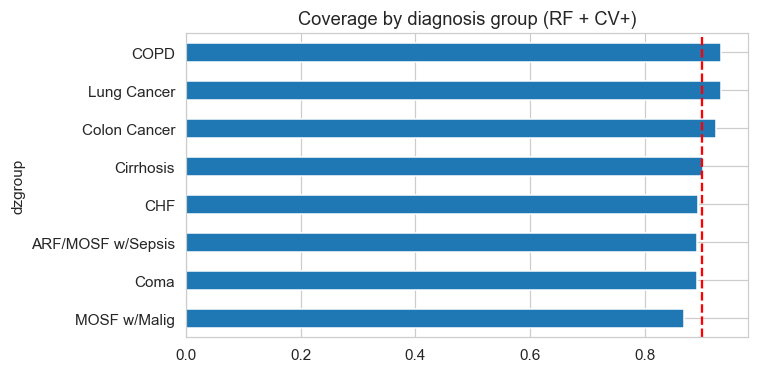

In [34]:
g = (allp[(allp["Model"] == "Random forest") & (allp["CP method"] == "CV+")]
        .groupby("dzgroup")["covered"].mean().sort_values())
plt.figure(figsize=(7, 3.5)); g.plot.barh(); plt.axvline(1 - ALPHA, color="red", ls="--")
plt.title("Coverage by diagnosis group (RF + CV+)"); plt.tight_layout()
plt.savefig("fig_coverage_group.png"); plt.show()

### 11.4 Variability across repetitions and coverage by predicted-cost quintile

Left: distribution of the coverage over the N_REP random splits. Right: coverage by quintile of the predicted cost for every model/method, to show where the intervals are too tight or too wide.

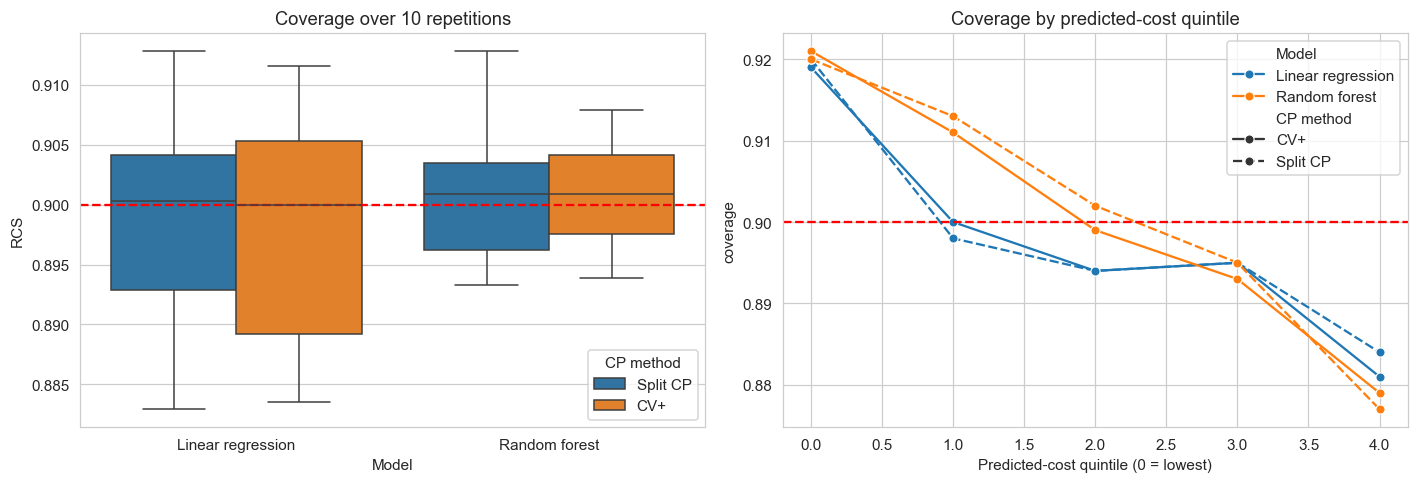

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=res, x="Model", y="RCS", hue="CP method", ax=ax[0])
ax[0].axhline(1 - ALPHA, color="red", ls="--"); ax[0].set_title(f"Coverage over {N_REP} repetitions")

qplot = by_q.reset_index()
sns.lineplot(data=qplot, x="pred_quintile", y="coverage", hue="Model", style="CP method",
             marker="o", ax=ax[1])
ax[1].axhline(1 - ALPHA, color="red", ls="--")
ax[1].set_xlabel("Predicted-cost quintile (0 = lowest)"); ax[1].set_title("Coverage by predicted-cost quintile")
plt.tight_layout(); plt.savefig("fig_coverage_variability.png"); plt.show()

## 12. Cross-check with MAPIE

### 12.1 Validation against the MAPIE library

Re-runs Split CP and CV+ with the reference library **MAPIE** on the same split as repetition 0 (seed = `SEED`) and compares coverage and width with our from-scratch implementation. Results should be very close. If MAPIE is missing, install it with `pip install mapie`.

In [36]:
try:
    from mapie.regression import SplitConformalRegressor, CrossConformalRegressor
    from mapie.metrics.regression import regression_coverage_score, regression_mean_width_score
    MAPIE_OK = True
except ImportError:
    MAPIE_OK = False
    print("MAPIE is not installed. Run: pip install mapie")

if MAPIE_OK:
    X_d, X_t, y_d, y_t = train_test_split(X, y, test_size=0.20, random_state=SEED)
    X_tr, X_cal, y_tr, y_cal = train_test_split(X_d, y_d, test_size=0.25, random_state=SEED)
    mapie_rows = []
    for mname, kind in MODELS:
        scr = SplitConformalRegressor(estimator=make_model(kind), confidence_level=1 - ALPHA, prefit=False)
        scr.fit(X_tr, y_tr); scr.conformalize(X_cal, y_cal)
        _, pis = scr.predict_interval(X_t)
        cov, wid = regression_coverage_score(y_t, pis)[0], regression_mean_width_score(pis)[0]
        print(mname, "| Split CP:", cov, wid)
        mapie_rows.append({"Model": mname, "CP method": "Split CP", "RCS (MAPIE)": cov, "RMWS log (MAPIE)": wid})

        ccr = CrossConformalRegressor(estimator=make_model(kind), confidence_level=1 - ALPHA,
                                      method="plus", cv=K, random_state=SEED)
        ccr.fit_conformalize(X_d, y_d)
        _, pis = ccr.predict_interval(X_t)
        cov, wid = regression_coverage_score(y_t, pis)[0], regression_mean_width_score(pis)[0]
        print(mname, "| CV+     :", cov, wid)
        mapie_rows.append({"Model": mname, "CP method": "CV+", "RCS (MAPIE)": cov, "RMWS log (MAPIE)": wid})

Linear regression | Split CP: 0.8969512195121951 1.8457732979920003
Linear regression | CV+     : 0.9079268292682927 1.8641334285760927
Random forest | Split CP: 0.8957317073170732 1.2168755218535559
Random forest | CV+     : 0.9036585365853659 1.2439513834050007


### 12.2 Side-by-side comparison: our implementation vs MAPIE

Merges the MAPIE results with our results for repetition 0 (same train/test split). Small differences are expected, mainly because the CV+ fold assignment can differ between the two implementations.

In [37]:
if MAPIE_OK:
    ours = (res[res["rep"] == 0][["Model", "CP method", "RCS", "RMWS (log)"]]
            .rename(columns={"RCS": "RCS (ours)", "RMWS (log)": "RMWS log (ours)"}))
    comparison = ours.merge(pd.DataFrame(mapie_rows), on=["Model", "CP method"])
    print(comparison.round(4).to_string(index=False))

            Model CP method  RCS (ours)  RMWS log (ours)  RCS (MAPIE)  RMWS log (MAPIE)
Linear regression  Split CP      0.8982           1.8466       0.8970            1.8458
Linear regression       CV+      0.9079           1.8641       0.9079            1.8641
    Random forest  Split CP      0.8957           1.2172       0.8957            1.2169
    Random forest       CV+      0.9037           1.2440       0.9037            1.2440


## 13. Saving results and conclusions

### 13.1 Export tables

Saves the baseline results, the per-repetition results and the summary tables as CSV files so they can be used directly in the report.

In [38]:
baseline.to_csv("ml_baseline_results.csv", index=False)
res.to_csv("cp_results_by_repetition.csv", index=False)
summary.to_csv("cp_summary.csv")
by_q.to_csv("cp_coverage_by_quintile.csv")
print("Saved: ml_baseline_results.csv, cp_results_by_repetition.csv, cp_summary.csv, cp_coverage_by_quintile.csv")

Saved: ml_baseline_results.csv, cp_results_by_repetition.csv, cp_summary.csv, cp_coverage_by_quintile.csv
